# Deep Learning - Assignment 1
### Training-Testing Neural Net with MNIST Dataset using PyTorch
#### Group No. 5

##### Task 1 - Install PyTorch

In [1]:
%pip install torch torchvision matplotlib

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------------------------

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu


##### Task 2 - Download and Load the Dataset

In [2]:
from torch.utils.data import random_split

# Convert images to tensors and normalize them
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Download and load MNIST
full_train = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_set   = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Split the 60,000 training images into 50,000 for training and 10,000 for validation
train_set, val_set = random_split(full_train, [50000, 10000],
                                  generator=torch.Generator().manual_seed(42))

# Create DataLoaders
batch_size = 32
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_set,   batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_set,  batch_size=batch_size, shuffle=False)

print("Dataset loaded successfully!")
print("Training images:  ", len(train_set))
print("Validation images:", len(val_set))
print("Test images:      ", len(test_set))

100%|██████████| 9.91M/9.91M [00:18<00:00, 550kB/s] 
100%|██████████| 28.9k/28.9k [00:00<00:00, 153kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 851kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.51MB/s]

Dataset loaded successfully!
Training images:   50000
Validation images: 10000
Test images:       10000


##### Task 3 - Inspect the Dataset

In [3]:
# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

# Print the size of the image and label tensors
print("Images tensor size:", images.shape)
print("Labels tensor size:", labels.shape)
print("Single image size: ", images[0].shape)

Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])
Single image size:  torch.Size([1, 28, 28])


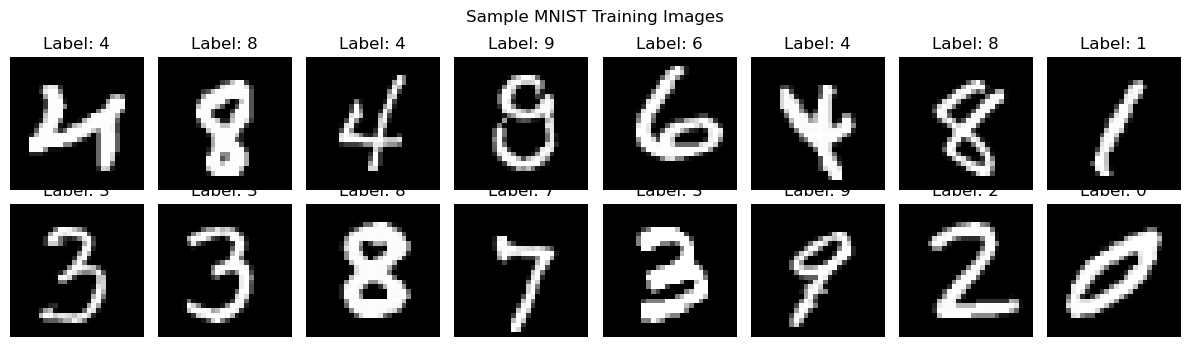

In [8]:
# Visualize the first 16 images in the batch with their labels
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")  # squeeze removes the channel dimension: [1, 28, 28] -> [28, 28]
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.suptitle("Sample MNIST Training Images")
plt.tight_layout()
plt.show()

##### Task 4 - Creating A Simple Network

In [9]:
class SimpleNet(nn.Module):
    def __init__(self, input_size=784, hidden_size=128, num_classes=10):
        super().__init__()
        # Fully connected layer: input -> hidden
        self.fc1 = nn.Linear(input_size, hidden_size)
        # ReLU activation (non-linearity)
        self.relu = nn.ReLU()
        # Fully connected layer: hidden -> output
        self.fc2 = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # Flatten from (N, 1, 28, 28) to (N, 784), keeping the batch dimension
        x = torch.flatten(x, 1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)  # No softmax here: CrossEntropyLoss applies it internally
        return x

model = SimpleNet()
print(model)

SimpleNet(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [10]:
# Take one batch to verify the network works as required
images, labels = next(iter(train_loader))

print("Input shape before flatten:", images.shape)
print("Shape after flatten:       ", torch.flatten(images, 1).shape)

outputs = model(images)
print("Output shape:              ", outputs.shape)

# Count the trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Total trainable parameters:", total_params)

Input shape before flatten: torch.Size([32, 1, 28, 28])
Shape after flatten:        torch.Size([32, 784])
Output shape:               torch.Size([32, 10])
Total trainable parameters: 101770


##### Task 5 - Training Function

In [11]:
def train(net, dataloader, epochs=5, lr=0.01, momentum=0.9, print_every=200, verbose=True):
    # Loss function: applies softmax + negative log likelihood
    criterion = nn.CrossEntropyLoss()
    # Optimizer: stochastic gradient descent with learning rate and momentum
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum)

    batch_losses = []   # loss of every mini-batch
    epoch_losses = []   # average loss per epoch
    epoch_accs = []     # accuracy per epoch

    net.train()  # put the network in training mode
    for epoch in range(epochs):
        running_loss, running_correct, running_total = 0.0, 0, 0
        epoch_loss_sum, epoch_correct, epoch_total = 0.0, 0, 0

        for batch_idx, (images, labels) in enumerate(dataloader, start=1):
            optimizer.zero_grad()              # 1. clear old gradients
            outputs = net(images)              # 2. forward pass
            loss = criterion(outputs, labels)  # 3. compute the loss
            loss.backward()                    # 4. backpropagation
            optimizer.step()                   # 5. update the weights

            # Track loss and accuracy
            batch_losses.append(loss.item())
            preds = outputs.argmax(dim=1)
            correct = (preds == labels).sum().item()

            running_loss += loss.item()
            running_correct += correct
            running_total += labels.size(0)
            epoch_loss_sum += loss.item()
            epoch_correct += correct
            epoch_total += labels.size(0)

            # Print debug information every `print_every` batches
            if verbose and batch_idx % print_every == 0:
                print(f"Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx}/{len(dataloader)}] | "
                      f"Loss: {running_loss/print_every:.4f} | "
                      f"Accuracy: {100*running_correct/running_total:.2f}%")
                running_loss, running_correct, running_total = 0.0, 0, 0

        # Save epoch results
        epoch_losses.append(epoch_loss_sum / len(dataloader))
        epoch_accs.append(100 * epoch_correct / epoch_total)
        if verbose:
            print(f"==> Epoch {epoch+1} finished | Avg Loss: {epoch_losses[-1]:.4f} | "
                  f"Accuracy: {epoch_accs[-1]:.2f}%\n")

    return batch_losses, epoch_losses, epoch_accs

#### Task 6 - Training Network

In [12]:
# Fix the random seed so results are reproducible
torch.manual_seed(42)

# Instantiate a new network
net = SimpleNet(hidden_size=128)

# Train the network
batch_losses, epoch_losses, epoch_accs = train(
    net, train_loader,
    epochs=5,
    lr=0.01,
    momentum=0.9,
    print_every=200
)

Epoch [1/5] | Batch [200/1563] | Loss: 0.5556 | Accuracy: 83.05%
Epoch [1/5] | Batch [400/1563] | Loss: 0.2854 | Accuracy: 91.14%
Epoch [1/5] | Batch [600/1563] | Loss: 0.2348 | Accuracy: 93.00%
Epoch [1/5] | Batch [800/1563] | Loss: 0.1849 | Accuracy: 94.80%
Epoch [1/5] | Batch [1000/1563] | Loss: 0.1679 | Accuracy: 95.03%
Epoch [1/5] | Batch [1200/1563] | Loss: 0.1661 | Accuracy: 94.92%
Epoch [1/5] | Batch [1400/1563] | Loss: 0.1517 | Accuracy: 95.33%
==> Epoch 1 finished | Avg Loss: 0.2374 | Accuracy: 92.83%

Epoch [2/5] | Batch [200/1563] | Loss: 0.0970 | Accuracy: 96.97%
Epoch [2/5] | Batch [400/1563] | Loss: 0.1017 | Accuracy: 96.81%
Epoch [2/5] | Batch [600/1563] | Loss: 0.0942 | Accuracy: 97.44%
Epoch [2/5] | Batch [800/1563] | Loss: 0.1039 | Accuracy: 96.92%
Epoch [2/5] | Batch [1000/1563] | Loss: 0.0937 | Accuracy: 97.09%
Epoch [2/5] | Batch [1200/1563] | Loss: 0.1068 | Accuracy: 96.89%
Epoch [2/5] | Batch [1400/1563] | Loss: 0.0876 | Accuracy: 97.41%
==> Epoch 2 finished | A

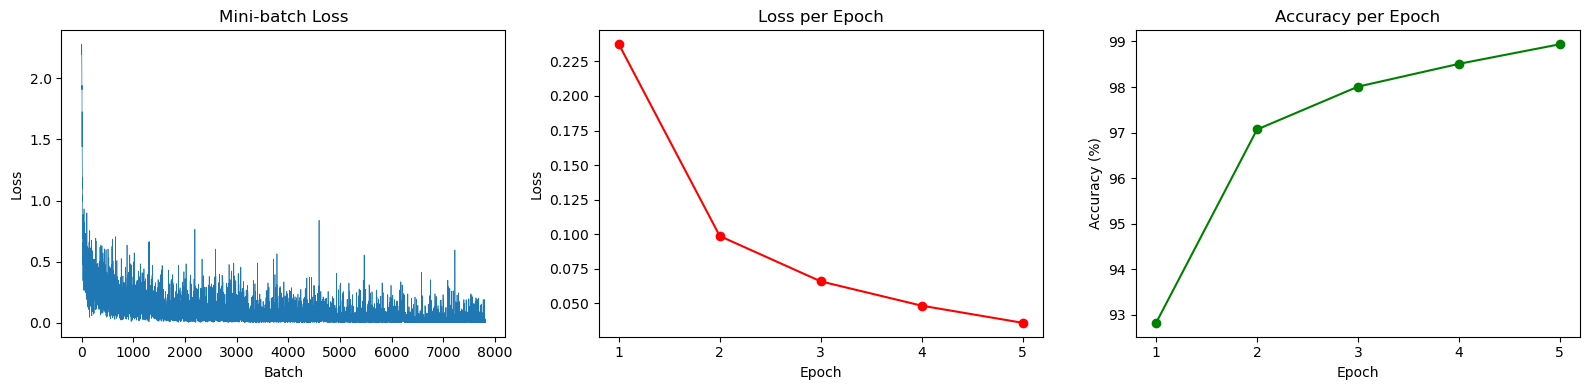

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Loss of every mini-batch
axes[0].plot(batch_losses, linewidth=0.5)
axes[0].set_title("Mini-batch Loss")
axes[0].set_xlabel("Batch")
axes[0].set_ylabel("Loss")

# 2. Average loss per epoch
epochs_range = range(1, len(epoch_losses) + 1)
axes[1].plot(epochs_range, epoch_losses, marker="o", color="red")
axes[1].set_title("Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(list(epochs_range))

# 3. Accuracy per epoch
axes[2].plot(epochs_range, epoch_accs, marker="o", color="green")
axes[2].set_title("Accuracy per Epoch")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Accuracy (%)")
axes[2].set_xticks(list(epochs_range))

plt.tight_layout()
plt.show()

### Task 7 - Testing Network

In [14]:
def evaluate(net, dataloader):
    criterion = nn.CrossEntropyLoss()
    net.eval()  # put the network in evaluation mode
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():  # no gradients needed for testing
        for images, labels in dataloader:
            outputs = net(images)
            total_loss += criterion(outputs, labels).item()
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / len(dataloader)
    accuracy = 100 * correct / total
    return avg_loss, accuracy

# Evaluate on the full test set (10,000 images)
test_loss, test_acc = evaluate(net, test_loader)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

Test Loss: 0.0876
Test Accuracy: 97.58%


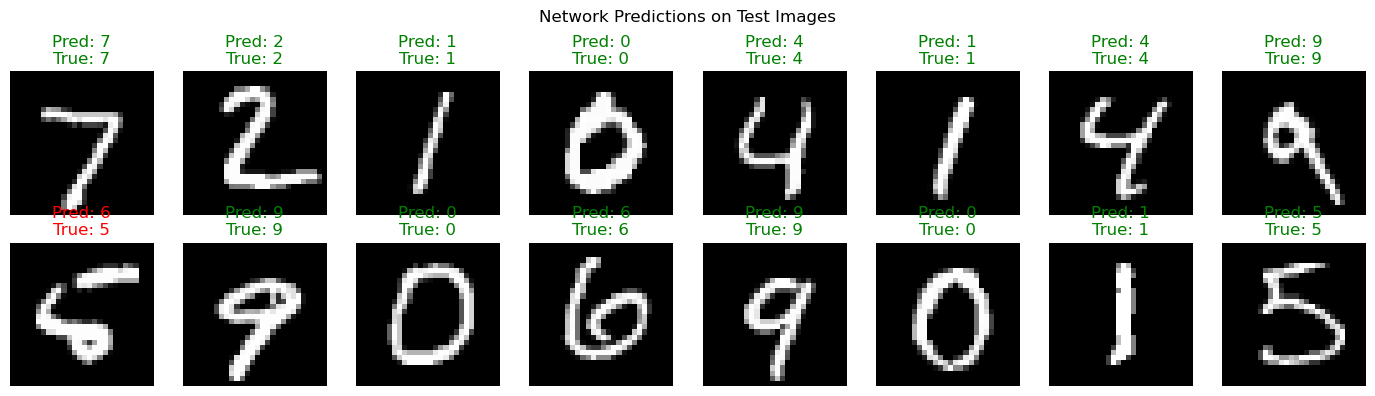

Correct predictions in this sample: 15/16


In [15]:
# Take one batch from the test set
images, labels = next(iter(test_loader))

net.eval()
with torch.no_grad():
    outputs = net(images)
    preds = outputs.argmax(dim=1)

# Show the first 16 test images with predicted and true labels
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    color = "green" if preds[i] == labels[i] else "red"  # green = correct, red = wrong
    ax.set_title(f"Pred: {preds[i].item()}\nTrue: {labels[i].item()}", color=color)
    ax.axis("off")

plt.suptitle("Network Predictions on Test Images")
plt.tight_layout()
plt.show()

print(f"Correct predictions in this sample: {(preds[:16] == labels[:16]).sum().item()}/16")

#### Task 8 - Tuning the parameters and model architecture

In [16]:
import pandas as pd

class FlexibleNet(nn.Module):
    """A network with any number of hidden layers and neurons."""
    def __init__(self, hidden_sizes=[128], input_size=784, num_classes=10):
        super().__init__()
        layers = []
        prev_size = input_size
        for h in hidden_sizes:
            layers.append(nn.Linear(prev_size, h))
            layers.append(nn.ReLU())
            prev_size = h
        layers.append(nn.Linear(prev_size, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, 1)
        return self.net(x)


def run_experiment(hidden_sizes, lr, momentum, epochs=3):
    """Train a model with the given settings and evaluate it on the validation set."""
    torch.manual_seed(42)  # same starting weights for a fair comparison
    model = FlexibleNet(hidden_sizes)
    _, train_losses, train_accs = train(model, train_loader, epochs=epochs,
                                        lr=lr, momentum=momentum, verbose=False)
    val_loss, val_acc = evaluate(model, val_loader)
    return model, train_losses[-1], train_accs[-1], val_loss, val_acc

In [17]:
learning_rates = [0.001, 0.01, 0.1]
momentums = [0.0, 0.5, 0.9]

param_results = []
for lr in learning_rates:
    for m in momentums:
        _, tr_loss, tr_acc, val_loss, val_acc = run_experiment([128], lr, m)
        param_results.append({"Learning Rate": lr, "Momentum": m,
                              "Train Loss": round(tr_loss, 4), "Train Acc (%)": round(tr_acc, 2),
                              "Val Loss": round(val_loss, 4), "Val Acc (%)": round(val_acc, 2)})
        print(f"lr={lr}, momentum={m} -> Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

param_df = pd.DataFrame(param_results)
display(param_df)

# Pick the best settings (highest validation accuracy)
best_params = param_df.loc[param_df["Val Acc (%)"].idxmax()]
best_lr, best_momentum = best_params["Learning Rate"], best_params["Momentum"]
print(f"\nBest parameters: lr={best_lr}, momentum={best_momentum} "
      f"-> Val Loss: {best_params['Val Loss']}, Val Acc: {best_params['Val Acc (%)']}%")

lr=0.001, momentum=0.0 -> Val Loss: 0.4233, Val Acc: 88.75%
lr=0.001, momentum=0.5 -> Val Loss: 0.3434, Val Acc: 90.12%
lr=0.001, momentum=0.9 -> Val Loss: 0.2043, Val Acc: 94.13%
lr=0.01, momentum=0.0 -> Val Loss: 0.2043, Val Acc: 94.05%
lr=0.01, momentum=0.5 -> Val Loss: 0.1506, Val Acc: 95.69%
lr=0.01, momentum=0.9 -> Val Loss: 0.1008, Val Acc: 96.89%
lr=0.1, momentum=0.0 -> Val Loss: 0.1012, Val Acc: 96.95%
lr=0.1, momentum=0.5 -> Val Loss: 0.1136, Val Acc: 96.98%
lr=0.1, momentum=0.9 -> Val Loss: 1.1009, Val Acc: 73.83%


,Learning Rate,Momentum,Train Loss,Train Acc (%),Val Loss,Val Acc (%)
0,0.001,0.0,0.4492,88.18,0.4233,88.75
1,0.001,0.5,0.3533,90.04,0.3434,90.12
2,0.001,0.9,0.2074,94.15,0.2043,94.13
3,0.010,0.0,0.2065,94.21,0.2043,94.05
4,0.010,0.5,0.1440,95.99,0.1506,95.69
5,0.010,0.9,0.0659,98.01,0.1008,96.89
6,0.100,0.0,0.0664,97.97,0.1012,96.95
7,0.100,0.5,0.0758,97.63,0.1136,96.98
8,0.100,0.9,0.9520,72.56,1.1009,73.83



Best parameters: lr=0.1, momentum=0.5 -> Val Loss: 0.1136, Val Acc: 96.98%


In [18]:
architectures = [[64], [128], [256], [128, 64], [256, 128], [256, 128, 64]]

arch_results = []
for arch in architectures:
    _, tr_loss, tr_acc, val_loss, val_acc = run_experiment(arch, best_lr, best_momentum)
    arch_results.append({"Hidden Layers": len(arch), "Neurons": str(arch),
                         "Train Loss": round(tr_loss, 4), "Train Acc (%)": round(tr_acc, 2),
                         "Val Loss": round(val_loss, 4), "Val Acc (%)": round(val_acc, 2)})
    print(f"Architecture {arch} -> Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

arch_df = pd.DataFrame(arch_results)
display(arch_df)

best_arch_row = arch_df.loc[arch_df["Val Acc (%)"].idxmax()]
best_arch = eval(best_arch_row["Neurons"])
print(f"\nBest architecture: {best_arch} "
      f"-> Val Loss: {best_arch_row['Val Loss']}, Val Acc: {best_arch_row['Val Acc (%)']}%")

Architecture [64] -> Val Loss: 0.1452, Val Acc: 96.04%
Architecture [128] -> Val Loss: 0.1136, Val Acc: 96.98%
Architecture [256] -> Val Loss: 0.1212, Val Acc: 96.62%
Architecture [128, 64] -> Val Loss: 0.1256, Val Acc: 96.44%
Architecture [256, 128] -> Val Loss: 0.1071, Val Acc: 96.94%
Architecture [256, 128, 64] -> Val Loss: 0.1005, Val Acc: 97.14%


,Hidden Layers,Neurons,Train Loss,Train Acc (%),Val Loss,Val Acc (%)
0,1,[64],0.0976,97.05,0.1452,96.04
1,1,[128],0.0758,97.63,0.1136,96.98
2,1,[256],0.0595,98.11,0.1212,96.62
3,2,"[128, 64]",0.0799,97.49,0.1256,96.44
4,2,"[256, 128]",0.0644,98.02,0.1071,96.94
5,3,"[256, 128, 64]",0.0731,97.70,0.1005,97.14



Best architecture: [256, 128, 64] -> Val Loss: 0.1005, Val Acc: 97.14%


In [19]:
# Train the best configuration for 5 epochs and evaluate on the test set
torch.manual_seed(42)
best_model = FlexibleNet(best_arch)
train(best_model, train_loader, epochs=5, lr=best_lr, momentum=best_momentum, verbose=False)

final_test_loss, final_test_acc = evaluate(best_model, test_loader)
print("===== Best Model =====")
print(f"Architecture:  {best_arch}")
print(f"Learning rate: {best_lr}")
print(f"Momentum:      {best_momentum}")
print(f"Test Loss:     {final_test_loss:.4f}")
print(f"Test Accuracy: {final_test_acc:.2f}%")

===== Best Model =====
Architecture:  [256, 128, 64]
Learning rate: 0.1
Momentum:      0.5
Test Loss:     0.0835
Test Accuracy: 97.73%
